<div align="center">

# 🌍💻 LangCode 2027 · Shared Task 1 · Starter Notebook
## 🔧 Fine-tuning with 🐯 TigerCoder-1B

**Multilingual Code Generation** · LangCode 2027, the First Language and Code Workshop (NAACL 2027)<br>
*One problem, 50 natural languages, one correct program*

[🏠 Task website](https://langcode2027.github.io/task1/) · [📦 Data](https://langcode2027.github.io/task1/data/) · [🚀 Participate](https://langcode2027.github.io/task1/participate/) · [🏆 Leaderboard](https://langcode2027.github.io/task1/leaderboard/) · [🧪 CodaBench](https://www.codabench.org/competitions/18470/)

</div>

---

👋 **Welcome!** This notebook takes you from nothing to a file you can submit on CodaBench, in one run. It shows everything on the **trial set** first, where all the tests are public, so you can see how the official scorer judges each solution. Then it writes your **dev** submission.

| Step | What happens |
|:--:|---|
| 🛠️ **1** | Install the six toolchains, load the libraries |
| 📦 **2** | Download the data and the official scorer |
| 📏 **3** | Understand Pass@1 and check the scorer on trial |
| ✂️ **4** | Split trial: 80 tasks to train on, 20 held out |
| 🐯 **5** | Score TigerCoder-1B on the held-out 20 before training |
| 🔧 **6** | Fine-tune it with LoRA on the 80 trial tasks |
| 📈 **7** | Score the held-out 20 again: did it help? |
| 📝 **8** | Solve the 500 dev tasks with the fine-tuned model |
| 📤 **9** | Write, check and zip `submission.zip` |
| 🚀 **10** | Submit on CodaBench |

⚡ **Runtime:** a free Colab **T4 GPU** is enough (Runtime → Change runtime type → T4 GPU). A full run takes about 35 minutes, most of it spent writing the 500 dev solutions.

🔁 There is a twin notebook that does **prompting**; both are on the [Data page](https://langcode2027.github.io/task1/data/).

In [1]:
#@title 🧩 One extra package for fine-tuning
EXTRA_PACKAGES = {'peft': '0.11'}   # fine-tuning needs PEFT (LoRA); the setup below installs it

## 🛠️ 1 · Setup

The scorer runs every solution in its own language, so we install the **six toolchains** the competition uses: 🐍 Python, 🟨 JavaScript (Node 22), ⚙️ C (gcc), 🐘 PHP, 💎 Ruby and 🌙 Lua. Python and gcc already come with Colab.

In [2]:
#@title 🛠️ Install the six language toolchains (about 1 minute)
import os, sys, re, json, time, random, shutil, subprocess, zipfile, urllib.request, warnings, logging
os.environ['HF_HUB_DISABLE_IMPLICIT_TOKEN'] = '1'          # TigerCoder-1B is public: no Hugging Face token needed
os.environ['HF_HUB_VERBOSITY'] = 'error'; os.environ['TRANSFORMERS_VERBOSITY'] = 'error'
warnings.filterwarnings('ignore'); logging.getLogger('huggingface_hub').setLevel(logging.ERROR)

def sh(cmd):
    r = subprocess.run(cmd, shell=True, capture_output=True, text=True)
    if r.returncode:
        print(r.stdout[-1500:], r.stderr[-1500:]); raise RuntimeError(f'failed: {cmd}')
    return r.stdout.strip()

if not shutil.which('php') or not shutil.which('ruby') or not shutil.which('lua5.4'):
    print('📥 installing PHP, Ruby and Lua ...')
    sh('apt-get -qq update && DEBIAN_FRONTEND=noninteractive apt-get -qq install -y php-cli ruby lua5.4 > /dev/null')
sh('ln -sf "$(command -v lua5.4)" /usr/local/bin/lua')
if not sh('node --version 2>/dev/null || true').startswith('v22'):
    print('📥 installing Node 22 ...')
    sh('curl -fsSL https://nodejs.org/dist/v22.11.0/node-v22.11.0-linux-x64.tar.xz | tar -xJ -C /usr/local --strip-components=1')
# the scorer runs solutions with a fixed PATH (/usr/local/bin:/usr/bin:/bin); Colab keeps its Node in /tools/node
for tool in ['node', 'php', 'ruby', 'gcc']:
    where = shutil.which(tool)
    if where and not os.path.exists(f'/usr/local/bin/{tool}') and not where.startswith(('/usr/bin', '/bin')):
        os.symlink(where, f'/usr/local/bin/{tool}')

VERSIONS = {'🐍 Python': 'python3 --version', '🟨 Node': 'node --version', '⚙️ gcc': 'gcc --version | head -1',
            '🐘 PHP': 'php --version | head -1', '💎 Ruby': 'ruby --version', '🌙 Lua': 'lua -v'}
for name, cmd in VERSIONS.items():
    print(f'✅ {name:10s} {sh(cmd + " 2>&1")[:60]}')

📥 installing PHP, Ruby and Lua ...
✅ 🐍 Python   Python 3.13.16
✅ 🟨 Node     v22.23.4
✅ ⚙️ gcc     gcc (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0
✅ 🐘 PHP      PHP 8.3.6 (cli) (built: Oct 19 2026 15:16:58) (NTS)
✅ 💎 Ruby     ruby 3.2.3 (2024-01-18 revision 52bb2ac0a6) [x86_64-linux-gn
✅ 🌙 Lua      Lua 5.4.6  Copyright (C) 1994-2023 Lua.org, PUC-Rio


In [3]:
#@title 📚 Load the libraries and check the GPU
import importlib.metadata as im
from packaging.version import Version
need = {'transformers': '4.56', 'accelerate': '0.30', **globals().get('EXTRA_PACKAGES', {})}

def version_of(pkg):
    try:
        return im.version(pkg)
    except im.PackageNotFoundError:
        return None

todo = [f'{p}>={v}' for p, v in need.items() if not version_of(p) or Version(version_of(p)) < Version(v)]
if todo:
    print('📥 pip install', *todo); sh(f'{sys.executable} -m pip install -q ' + ' '.join(f'"{x}"' for x in todo))
if 'peft' in need and version_of('torchao') and Version(version_of('torchao')) < Version('0.16'):
    sh(f'{sys.executable} -m pip uninstall -q -y torchao')   # recent PEFT refuses old torchao; LoRA does not need it

import torch, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from IPython.display import display, HTML, Markdown
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
assert torch.cuda.is_available(), '🚫 No GPU found: Runtime → Change runtime type → T4 GPU, then run again.'
GPU = torch.cuda.get_device_name(0)
# bfloat16 on Ampere or newer (A100, L4); a T4 only emulates it, so float32 is faster there. Gemma 3 overflows in float16.
DTYPE = torch.bfloat16 if torch.cuda.get_device_capability(0)[0] >= 8 else torch.float32
print(f'🎮 GPU: {GPU} · weights in {str(DTYPE).replace("torch.", "")}')

🎮 GPU: Tesla T4 · weights in float32


## 📦 2 · Data and scorer

Everything comes from the [Data page](https://langcode2027.github.io/task1/data/) of the task website:

| File | Tasks | Tests in the file | Used for |
|---|:--:|:--:|---|
| `trial.jsonl` | 100 | all 5 ✅ + a reference solution | learning, checking, scoring yourself |
| `dev.jsonl` | 500 | 2 of 5 👀 | **Development phase** submissions |
| `test.jsonl` | 1,000 | 2 of 5 👀 | **Test phase** submissions, from Jan 8, 2027 |
| `scorer.zip` | | | the official scorer, the same program CodaBench runs |

Each line is one task with `task_id`, `entry` (the function name), `prompt` and `tests`. The natural language is **not** given, and neither is the programming language: you read it from the prompt.

In [4]:
#@title 📥 Download the data and the scorer
BASE = 'https://langcode2027.github.io/task1/data/files/'
for f in ['trial.jsonl', 'dev.jsonl', 'scorer.zip']:
    if not os.path.exists(f):
        urllib.request.urlretrieve(BASE + f, f)
if not os.path.exists('scorer/score.py'):
    zipfile.ZipFile('scorer.zip').extractall('scorer')

def read_jsonl(path):
    return [json.loads(l) for l in open(path, encoding='utf-8') if l.strip()]

trial, dev = read_jsonl('trial.jsonl'), read_jsonl('dev.jsonl')
REF_TRIAL = {r['task_id']: r for r in read_jsonl('scorer/reference_trial/reference.jsonl')}   # pl, signature, all tests
print(f'📦 trial: {len(trial)} tasks · dev: {len(dev)} tasks · scorer: {sorted(os.listdir("scorer"))}')

📦 trial: 100 tasks · dev: 500 tasks · scorer: ['README.md', 'lc_harness.py', 'lc_sandbox.py', 'reference_trial', 'score.py']


### 🔎 What does a task look like?

The **prompt** is a function signature with the problem as a comment, written in one of 50 natural languages. Your system writes the whole function in the same programming language.

In [5]:
#@title 🔎 Show one trial task
ex = trial[0]
display(HTML(f"""<div style="border:1px solid #ddd;border-radius:12px;padding:14px 18px;margin:6px 0">
<div style="font-size:12px;opacity:.65">📝 {ex['task_id']} · entry <code>{ex['entry']}</code></div>
<pre style="white-space:pre-wrap;font-size:13px;margin:8px 0">{ex['prompt']}</pre>
<div style="font-size:12px;opacity:.65">🧪 tests (inputs → expected output)</div>
<pre style="font-size:12px;margin:4px 0">{chr(10).join(json.dumps(t['in']) + '  →  ' + json.dumps(t['out']) for t in ex['tests'])}</pre></div>"""))

### 🧭 Which programming language is it?

The data files do not name the programming language, but the signature line gives it away. A small rule reads it, and we check the rule on the trial set, whose reference knows the answer.

🎯 language detection on trial: 100/100 correct


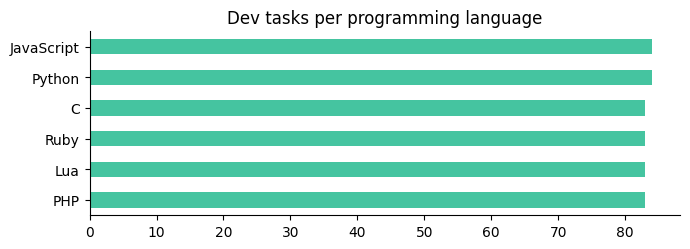

In [6]:
#@title 🧭 Detect the programming language
PL_NAME = {'python': '🐍 Python', 'javascript': '🟨 JavaScript', 'c': '⚙️ C', 'php': '🐘 PHP', 'ruby': '💎 Ruby', 'lua': '🌙 Lua'}

def detect_pl(prompt):
    lines = [l for l in prompt.strip().splitlines() if l.strip()]
    if lines[0].startswith('def ') and lines[0].rstrip().endswith(':'):
        return 'python'                        # Python: signature first, docstring after
    last = lines[-1].strip()
    if last.startswith('def '):
        return 'ruby'
    if last.startswith('function '):
        if '$' in last or re.search(r'\)\s*:\s*\??\w+\s*\{$', last):
            return 'php'
        return 'javascript' if last.endswith('{') else 'lua'
    return 'c'

hits = sum(detect_pl(r['prompt']) == REF_TRIAL[r['task_id']]['pl'] for r in trial)
print(f'🎯 language detection on trial: {hits}/{len(trial)} correct')
counts = pd.Series([PL_NAME[detect_pl(r['prompt'])].split(' ', 1)[1] for r in dev]).value_counts()   # chart fonts have no emoji
ax = counts.plot.barh(figsize=(7, 2.6), color='#45c4a0'); ax.invert_yaxis(); ax.set_title('Dev tasks per programming language')
ax.spines[['top', 'right']].set_visible(False); plt.tight_layout(); plt.show()

## 📏 3 · The metric: Pass@1

$$\text{Pass@1} \;=\; \frac{\text{tasks whose solution passes \textbf{all} its test cases}}{\text{all tasks}}$$

* **One solution per task**, no partial credit: one failing test case fails the task. ❌
* Each task has **5 test cases**. The dev and test files show 2; the other 3 are hidden 🙈, and all 5 are scored.
* Every solution runs in a sandbox: **1 s of CPU time**, 512 MB of memory, no network, no extra files, standard library only. Infinite loops are cut at 1 s. ⏱️
* The leaderboard also shows Pass@1 for each **language class** (Joshi et al., 2020) and each **programming language**; the ranking uses overall Pass@1. 🏆

The helper below runs the **official scorer** on a set of solutions. On the trial set it knows all 5 tests, so you get the exact score CodaBench would give.

In [7]:
#@title 📏 The official scorer, as a helper
def score(solutions, tasks=None, workdir='run'):
    """Score {task_id: solution} on trial tasks with the official scorer. Returns (scores, outcome per task)."""
    tasks = tasks or list(REF_TRIAL)
    shutil.rmtree(workdir, ignore_errors=True)
    os.makedirs(f'{workdir}/ref'); os.makedirs(f'{workdir}/res')
    with open(f'{workdir}/ref/reference.jsonl', 'w') as f:
        f.writelines(json.dumps(REF_TRIAL[t]) + '\n' for t in tasks)
    json.dump({'phase': 'trial', 'detailed_results': True}, open(f'{workdir}/ref/phase.json', 'w'))
    with open(f'{workdir}/res/submission.jsonl', 'w') as f:
        f.writelines(json.dumps({'task_id': t, 'solution': solutions[t]}) + '\n' for t in tasks if t in solutions)
    r = subprocess.run([sys.executable, 'scorer/score.py', workdir, f'{workdir}/out'], capture_output=True, text=True)
    if r.returncode:
        raise RuntimeError(r.stdout + r.stderr)
    s = json.load(open(f'{workdir}/out/scores.json'))
    html_ = open(f'{workdir}/out/detailed_results.html').read()
    outcome = dict(re.findall(r'<tr><td>(T1-[a-z]+-\d+)</td><td class="\w+">([a-z ]+)</td></tr>', html_))
    return s, outcome

def card(title, value, sub='', dark=False):
    bg, fg, bd = ('#16202f', '#fff', '#16202f') if dark else ('#fff', '#16202f', '#d0d7de')
    return (f'<div style="padding:12px 18px;border-radius:14px;background:{bg};color:{fg};border:1px solid {bd};min-width:110px">'
            f'<div style="font-size:11px;letter-spacing:.04em;opacity:.7">{title}</div>'
            f'<div style="font-size:28px;font-weight:700">{value}</div><div style="font-size:11px;opacity:.6">{sub}</div></div>')

def show_scores(s, label):
    pls = ''.join(card(PL_NAME[p].split(' ', 1)[1].upper(), f'{s[p]:.1f}', PL_NAME[p].split(' ')[0]) for p in PL_NAME)
    cls = ''.join(card(f'CLASS {k}', f'{s[f"tier_{k}"]:.1f}') for k in range(4) if f'tier_{k}' in s)
    main = card('PASS@1 · ' + label, '%.1f%%' % s['score'], '', True)
    display(HTML(f'<div style="display:flex;flex-wrap:wrap;gap:10px;margin:8px 0">{main}{pls}{cls}</div>'))

In [8]:
#@title ✅ Sanity check: the reference solutions score 100%
gold = {r['task_id']: r['canonical_solution'] for r in trial}
s, _ = score(gold); show_scores(s, 'reference solutions')
broken = [PL_NAME[p] for p in PL_NAME if s[p] < 100]
assert not broken, f'🚫 These toolchains do not work yet: {broken}. Run the setup cell again.'
print('✅ all six languages run: the scorer is ready')
s, _ = score({t: '' for t in gold}); print(f'🙃 empty submission → Pass@1 {s["score"]:.1f}%')

✅ all six languages run: the scorer is ready
🙃 empty submission → Pass@1 0.0%


## ✂️ 4 · Split the trial set

The trial set is the only data here that comes with full tests **and** reference solutions, so it is our training set. To see honestly whether training helps, we keep **20 trial tasks aside** and never train on them. 🙈

In [9]:
#@title ✂️ 80 tasks to train on, 20 held out
ids = sorted(REF_TRIAL); random.Random(SEED).shuffle(ids)
held_ids, train_ids = sorted(ids[:20]), set(ids[20:])
train_rows = [r for r in trial if r['task_id'] in train_ids]
held_rows = [r for r in trial if r['task_id'] in held_ids]
print(f'🏋️ train: {len(train_rows)} tasks · 🙈 held out: {len(held_rows)} tasks')
display(pd.DataFrame({'train': pd.Series([PL_NAME[detect_pl(r["prompt"])] for r in train_rows]).value_counts(),
                      'held out': pd.Series([PL_NAME[detect_pl(r["prompt"])] for r in held_rows]).value_counts()}).fillna(0).astype(int))

🏋️ train: 80 tasks · 🙈 held out: 20 tasks


,train,held out
⚙️ C,13,4
🌙 Lua,12,4
🐍 Python,14,3
🐘 PHP,15,2
💎 Ruby,12,4
🟨 JavaScript,14,3


## 🐯 5 · TigerCoder-1B before training

[TigerCoder-1B](https://huggingface.co/md-nishat-008/TigerCoder-1B) is a compact code model (Gemma 3, 1B parameters) trained to write code from Bangla instructions. First we prompt it as it is, on the 20 held-out tasks, to have a number to beat. 🎯

In [10]:
#@title 🐯 Load TigerCoder-1B and define the prompt
from transformers import AutoTokenizer, AutoModelForCausalLM

MODEL_ID = 'md-nishat-008/TigerCoder-1B'
BATCH, MAX_NEW_TOKENS = 16, 512

tok = AutoTokenizer.from_pretrained(MODEL_ID)
tok.padding_side = 'left'                      # left padding for batched generation
from transformers.utils import logging as hf_logging
hf_logging.set_verbosity_error()
model = AutoModelForCausalLM.from_pretrained(MODEL_ID, dtype=DTYPE).cuda().eval()
print(f'🐯 {MODEL_ID}: {sum(p.numel() for p in model.parameters()) / 1e9:.2f}B parameters')

LANG = {'python': 'Python', 'javascript': 'JavaScript', 'c': 'C', 'php': 'PHP', 'ruby': 'Ruby', 'lua': 'Lua'}

def instruction(prompt, pl):
    return (f'Complete the following {LANG[pl]} function. The problem is described in the comment. '
            f'Reply with the complete function only, in one ```{pl}``` code block, '
            f'with no main function, no tests and no printing.\n\n```{pl}\n{prompt}```')

def start_of_answer(prompt, pl):
    """We write the start of the answer ourselves: a code fence and the task's own prompt. The model then
    continues inside the function, in the right language (left alone, TigerCoder drifts to Python)."""
    return f'```{pl}\n{prompt}'

@torch.inference_mode()
def generate(model, prompts, desc='generate'):
    """Greedy continuations for a list of (prompt, pl) pairs, in batches."""
    model.eval(); answers = []
    for i in tqdm(range(0, len(prompts), BATCH), desc=desc):
        texts = [tok.apply_chat_template([{'role': 'user', 'content': instruction(p, pl)}], tokenize=False,
                                         add_generation_prompt=True) + start_of_answer(p, pl)
                 for p, pl in prompts[i:i + BATCH]]
        enc = tok(texts, return_tensors='pt', padding=True, add_special_tokens=False).to(model.device)
        out = model.generate(**enc, max_new_tokens=MAX_NEW_TOKENS, do_sample=False, pad_token_id=tok.pad_token_id)
        answers += tok.batch_decode(out[:, enc['input_ids'].shape[1]:], skip_special_tokens=True)
    return answers

# common imports and headers the body may need: the answer starts inside the function, so it cannot add them
PREAMBLE = {'python': 'import math, re, heapq, bisect, string\nfrom collections import Counter, defaultdict, deque\n'
                      'from functools import lru_cache, reduce\nfrom itertools import *\n',
            'c': '#include <limits.h>\n#include <ctype.h>\n#include <stdint.h>\n',
            'ruby': "require 'set'\n"}

def to_solution(answer, row, pl):
    """Prompt + the model's continuation up to the closing fence, cleaned up."""
    cont = answer.split('```')[0]
    if pl == 'python':                                       # the body must be indented: drop stray text before it
        lines = cont.split('\n')
        while lines and lines[0].strip() and not lines[0].startswith((' ', '\t')):
            lines.pop(0)
        cont = '\n'.join(lines)
    code = row['prompt'] + cont
    if pl == 'python':
        code = code.split('if __name__')[0]                 # drop demo code that would run
    if pl == 'c':
        code = re.split(r'\n\s*int\s+main\s*\(', code)[0]    # the scorer brings its own main
    if pl == 'php':
        code = re.sub(r'\?>\s*$', '', code.rstrip())
    return PREAMBLE.get(pl, '') + code.strip() + '\n'

config.json:   0%|          | 0.00/1.81k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.34k [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 33.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

chat_template.jinja:   0%|          | 0.00/1.53k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.00GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/340 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/197 [00:00<?, ?B/s]

🐯 md-nishat-008/TigerCoder-1B: 1.00B parameters


In [11]:
#@title 🎯 Score the held-out 20 before training
held_before = generate(model, [(r['prompt'], detect_pl(r['prompt'])) for r in held_rows], 'held-out, before')
sol_before = {r['task_id']: to_solution(a, r, detect_pl(r['prompt'])) for r, a in zip(held_rows, held_before)}
s_before, out_before = score(sol_before, held_ids)
show_scores(s_before, 'before training (held-out 20)')

held-out, before:   0%|          | 0/2 [00:00<?, ?it/s]

## 🔧 6 · Fine-tune with LoRA

**LoRA** trains small extra matrices next to the frozen model, so a 1B model trains in a few minutes on a T4. Each training example looks exactly like generation: the instruction, our start of the answer (code fence + prompt), and the **body of the reference solution** as the target. The loss counts only the target tokens.

Settings: rank 16, 3 epochs, learning rate 2e-4, one example at a time with an update every 4 examples. Gemma 3 has a 262K-word vocabulary, so small batches and gradient checkpointing keep memory within a T4. With only 80 examples this is a light touch, not a new skill. 🪶

trainable params: 13,045,760 || all params: 1,012,931,712 || trainable%: 1.2879
🏋️ 79 training examples (of 80 tasks)


epoch 1/3:   0%|          | 0/79 [00:00<?, ?it/s]

epoch 2/3:   0%|          | 0/79 [00:00<?, ?it/s]

epoch 3/3:   0%|          | 0/79 [00:00<?, ?it/s]

⏱️ trained in 5.1 min


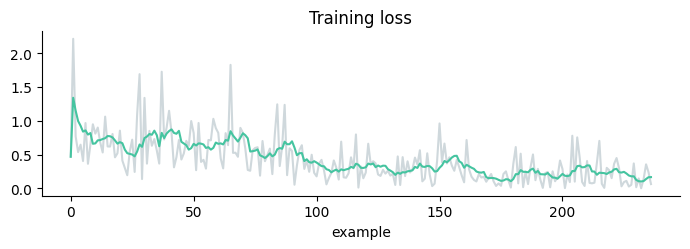

In [12]:
#@title 🔧 Train LoRA adapters on the 80 trial tasks
from peft import LoraConfig, get_peft_model

EPOCHS, LR, ACCUM, MAX_LEN = 3, 2e-4, 4, 1024     # one example at a time, an update every ACCUM examples

def train_example(r):
    """The same format as generation: the instruction, our start of the answer, and the reference body as the target."""
    pl = detect_pl(r['prompt'])
    lines = [l for l in r['prompt'].strip().splitlines() if l.strip()]
    sig = (lines[0] if pl == 'python' else lines[-1]).strip()
    sol = r['canonical_solution']; at = sol.find(sig)
    if at < 0 or any(l.strip() and not l.startswith('#include') for l in sol[:at].splitlines()):
        return None                                          # helpers above the function do not fit this format
    body = sol[at + len(sig):].lstrip('\n').rstrip()
    head = tok.apply_chat_template([{'role': 'user', 'content': instruction(r['prompt'], pl)}], tokenize=False,
                                   add_generation_prompt=True) + start_of_answer(r['prompt'], pl)
    ids_h = tok(head, add_special_tokens=False)['input_ids']
    ids_t = tok(body + '\n```' + tok.eos_token, add_special_tokens=False)['input_ids']
    return (ids_h + ids_t)[:MAX_LEN], ([-100] * len(ids_h) + ids_t)[:MAX_LEN]   # learn the answer only

lora = LoraConfig(r=16, lora_alpha=32, lora_dropout=0.05, task_type='CAUSAL_LM',
                  target_modules=['q_proj', 'k_proj', 'v_proj', 'o_proj', 'gate_proj', 'up_proj', 'down_proj'])
torch.cuda.empty_cache()
model.config.use_cache = False
model.gradient_checkpointing_enable(gradient_checkpointing_kwargs={'use_reentrant': False})   # saves GPU memory
model.enable_input_require_grads()
ft = get_peft_model(model, lora)
ft.print_trainable_parameters()

examples = [e for e in map(train_example, train_rows) if e]
print(f'🏋️ {len(examples)} training examples (of {len(train_rows)} tasks)')
opt = torch.optim.AdamW([p for p in ft.parameters() if p.requires_grad], lr=LR, weight_decay=0.0)
steps = EPOCHS * ((len(examples) + ACCUM - 1) // ACCUM)
sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1.0, (s + 1) / max(1, int(0.1 * steps))) * max(0.0, 1 - s / steps))

losses, t0, step = [], time.time(), 0
for epoch in range(EPOCHS):
    ft.train(); random.shuffle(examples)
    bar = tqdm(examples, desc=f'epoch {epoch + 1}/{EPOCHS}')
    for k, (x, y) in enumerate(bar):
        ids, lab = torch.tensor([x]).cuda(), torch.tensor([y]).cuda()
        loss = ft(input_ids=ids, labels=lab).loss
        (loss / ACCUM).backward(); losses.append(loss.item())
        if (k + 1) % ACCUM == 0 or k + 1 == len(examples):
            torch.nn.utils.clip_grad_norm_(ft.parameters(), 1.0)
            opt.step(); sched.step(); opt.zero_grad(); step += 1
        bar.set_postfix(loss=f'{loss.item():.3f}')
ft.eval(); model.config.use_cache = True
print(f'⏱️ trained in {(time.time() - t0) / 60:.1f} min')
smooth = pd.Series(losses).rolling(8, min_periods=1).mean()
plt.figure(figsize=(7, 2.6)); plt.plot(losses, color='#cfd8dc'); plt.plot(smooth, color='#45c4a0'); plt.title('Training loss'); plt.xlabel('example')
plt.gca().spines[['top', 'right']].set_visible(False); plt.tight_layout(); plt.show()

## 📈 7 · After training: the held-out 20 again

In [13]:
#@title 📈 Score the held-out 20 after training
held_after = generate(ft, [(r['prompt'], detect_pl(r['prompt'])) for r in held_rows], 'held-out, after')
sol_after = {r['task_id']: to_solution(a, r, detect_pl(r['prompt'])) for r, a in zip(held_rows, held_after)}
s_after, out_after = score(sol_after, held_ids)
show_scores(s_after, 'after training (held-out 20)')
delta = s_after['score'] - s_before['score']
display(HTML(f'<div style="font-size:18px;margin:6px 0">{"📈" if delta > 0 else "📉" if delta < 0 else "➖"} '
             f'Pass@1 on the held-out 20: <b>{s_before["score"]:.1f}% → {s_after["score"]:.1f}%</b> ({delta:+.1f} points)</div>'))
display(pd.DataFrame({'before': out_before, 'after': out_after}).value_counts().rename('tasks').to_frame())

held-out, after:   0%|          | 0/2 [00:00<?, ?it/s]

,,tasks
before,after,
wrong answer,wrong answer,7
passed,passed,3
runtime error,wrong answer,3
compile error,wrong answer,1
runtime error,passed,1
passed,runtime error,1
runtime error,runtime error,1
timeout,wrong answer,1
wrong answer,passed,1


⚠️ **20 tasks is a small sample:** one task is 5 points. Treat the difference as a hint, not a result.

🔭 **Small model, small sample.** This run fine-tunes TigerCoder-1B, a model with 1 billion parameters, on 80 trial tasks and checks it on 20. On dev it scores a little below the prompting notebook. Larger models and more training data will very likely give better results. Treat this run as the starting point to beat.

### 💡 Where to go from here

<details>
<summary><b>💡 Ideas worth a try (open when you are ready)</b></summary>

* 📚 **More data.** 100 trial tasks is very little. Multilingual code data such as [mHumanEval](https://aclanthology.org/2025.naacl-long.570/) (many natural languages) or [Bangla-Code-Instruct](https://huggingface.co/datasets/md-nishat-008/Bangla-Code-Instruct) gives the model far more to learn from. Any public data is allowed; describe it in your paper.
* 🔁 **All 100.** Once you have chosen your settings, train on all 100 trial tasks for the final run.
* 🎛️ **Settings.** Try the learning rate, rank, epochs and `MAX_LEN`; watch the held-out score, not the training loss.
* 🧪 **Use the two visible tests.** Every dev and test task shows 2 of its 5 tests: sample several answers and keep one that passes them.
* 🌍 **Balance.** Make sure every programming language and many natural languages are in the training data.
* 🦾 **Bigger models.** Any model or tool is allowed, as long as your system paper describes it.
</details>

## 📝 8 · Solve the dev set with the fine-tuned model

On a T4 this takes about 15–20 minutes. ☕

In [14]:
#@title 📝 Solve the 500 dev tasks
t0 = time.time()
dev_answers = generate(ft, [(r['prompt'], detect_pl(r['prompt'])) for r in dev], 'dev')
dev_solutions = {r['task_id']: to_solution(a, r, detect_pl(r['prompt'])) for r, a in zip(dev, dev_answers)}
print(f'⏱️ {len(dev)} dev solutions in {(time.time() - t0) / 60:.1f} min')

dev:   0%|          | 0/32 [00:00<?, ?it/s]

⏱️ 500 dev solutions in 17.2 min


## 📤 9 · Write, check and zip the dev submission

CodaBench takes a **`.zip`** with one file, **`submission.jsonl`**: one line per task, `{"task_id": ..., "solution": ...}`. The scorer's **format check** catches the problems that would make CodaBench reject the file. Run it every time: CodaBench does not show you why a file was rejected. 🕵️

In [15]:
#@title 📤 Write, check and download submission.zip
with open('submission.jsonl', 'w', encoding='utf-8') as f:
    for r in dev:
        f.write(json.dumps({'task_id': r['task_id'], 'solution': dev_solutions[r['task_id']]}, ensure_ascii=False) + '\n')
with zipfile.ZipFile('submission.zip', 'w', zipfile.ZIP_DEFLATED) as z:
    z.write('submission.jsonl')
print(sh(f'{sys.executable} scorer/score.py --check submission.zip dev.jsonl'))
print(f'📦 submission.zip: {os.path.getsize("submission.zip") / 1024:.0f} KB, {len(dev)} solutions')
try:
    from google.colab import files; files.download('submission.zip')
except Exception:
    print('💾 Download submission.zip from the Files panel on the left.')

Format OK: 500 solutions.
missing (scored as failed):        0
unknown task_id (ignored):         0
over 20 KB (rejected task):        0
uses an lc_ name (rejected task):  0
📦 submission.zip: 152 KB, 500 solutions


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 🚀 10 · Submit on CodaBench

1. Open [**the CodaBench competition**](https://www.codabench.org/competitions/18470/) and click **Register** (approval is automatic).
2. Go to **My Submissions** and pick the **Development** phase (the **Test** phase opens on Jan 8, 2027).
3. Fill in **Team name** and **Affiliation**: both appear on the leaderboard. Use the same team name every time.
4. Leave **Submit as** on **Yourself**. One CodaBench account per team ⚠️: submitting for the same team from several accounts can get the team disqualified.
5. Upload **`submission.zip`** and wait for **Finished**. Your Pass@1 appears on the [leaderboard](https://www.codabench.org/competitions/18470/#/results-tab), and the website's [leaderboard](https://langcode2027.github.io/task1/leaderboard/) picks it up at midnight EST. 🎉

Limits: 10 submissions a day and 300 in total in the Development phase; 3 a day and 10 in total in the Test phase. Failed submissions do not count.

❓ Questions? Ask in the [**Forum**](https://www.codabench.org/competitions/18470/#/forum) of the competition.

## 🧯 Common errors

| What you see | Why | Fix |
|---|---|---|
| 🚫 *No GPU found* | The runtime has no GPU | Runtime → Change runtime type → T4 GPU |
| 💥 *CUDA out of memory* | Batch too large | Lower `BATCH` and run the generation cell again |
| ❌ Status **Failed** on CodaBench | The file broke a format rule | Run the format check cell and fix what it reports |
| 🙈 Many *missing* tasks | Solutions not written for every `task_id` | Write one line for every dev task |
| ⏱️ Many *timeout* outcomes | Slow or looping code | Each task gets 1 s of CPU time; check loops and recursion |
| ⚙️ C tasks fail to compile | A `main` function, or a different signature | Keep the signature of the prompt; no `main` |
| 🌙 Lua or ⚙️ C answers look wrong | Language conventions | Lua tables start at 1; C returns a `malloc`'d array and sets `*out_len`, as the prompt's signature shows |